# GaroAvisa - Previsão do Tempo com IA

Global Solution 2026/2 - CitizenTech

Este notebook implementa o processo de **fine-tuning** do modelo `pierreguillou/gpt2-small-portuguese`. A partir de dados meteorológicos estruturados, o modelo aprende a gerar explicações em português, destacando alertas climáticos, recomendações diárias e notificações sobre alterações climáticas que impactam compromissos agendados.

### Pré-requisitos de Execução
* **Ambiente de Execução:** Runtime configurado com aceleração por hardware (**GPU T4**).
* **Arquivos Necessários:** O módulo `garoavisa_regras.py` deve estar armazenado no diretório `GaroAvisa_Colab` no Google Drive.

## Passo 1: Instalando dependências
Instalação e atuaalização das bibliotecas do ecossistema Hugging Face (`transformers`, `datasets`, `accelerate`) necessárias para o carregamento, tokenização e treinamento do modelo de linguagem.

In [ ]:
!pip install transformers[torch] datasets accelerate -U

print("Bibliotecas instaladas")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 49.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.3/608.3 kB 34.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 MB 60.9 MB/s  0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 23.0.1
    Uninstalling pyarrow-23.0.1:
      Successfully uninstalled pyarrow-23.0.1
  Attempting uninstall: datasets
    Found existing installation: datasets 4.8.5
    Uninstalling datasets-4.8.5:
      Successfully uninstalled datasets-4.8.5
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.1
    Uninstalling transformers-5.22.1:
      Successfully uninstalled transformers-5.22.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [transformers]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<

##Passo 2: Integração com Google Drive e Regras de Negócio

Conexão com o Google Drive e importação do arquivo `garoavisa_regras.py`, onde estão definidas as regras de alerta climático, o gerador dos dados de treinamento e as funções de validação das respostas.

In [ ]:
from google.colab import drive
import os
import sys
import json
import random
import math
import collections
import pandas as pd
import matplotlib.pyplot as plt

drive.mount('/content/drive')

PASTA = '/content/drive/MyDrive/GaroAvisa_Colab'
sys.path.append(PASTA)

import garoavisa_regras as ga

print("Arquivos na pasta:", os.listdir(PASTA))

Mounted at /content/drive
Arquivos na pasta: ['garoavisa_regras.py', '__pycache__']


## Passo 3: Geração do Dataset Sintético

Como não há uma base pública de previsões comentadas para este domínio, geramos um dataset sintético com 1.700 exemplos (usando semente fixa para reprodutibilidade). O script simula cenários climáticos, aplica as regras de alerta e estrutura os registros no formato `question` e `answer`, exibindo ao final a distribuição das amostras.

In [ ]:
caminho_dataset = f'{PASTA}/dataset_garoavisa_pt_br.json'

dataset_gerado = ga.gerar_dataset(quantidade=1700, semente=42)
ga.salvar_dataset(dataset_gerado, caminho_dataset)

with open(caminho_dataset, 'r', encoding='utf-8') as f:
    data_pt = json.load(f)

print(f"Total de exemplos: {len(data_pt)}")
print("Por tarefa:", dict(collections.Counter(item['tarefa'] for item in data_pt)))

contagem = collections.Counter()
for item in data_pt:
    if item['tarefa'] == 'dia':
        for alerta in ga.principais(ga.gerar_alertas(item['dados'])):
            contagem[alerta['tipo']] += 1
print("Alertas por tipo:", dict(contagem))

display(pd.DataFrame(data_pt)[['tarefa', 'question', 'answer']].head())

Total de exemplos: 1700
Por tarefa: {'dia': 1191, 'mudanca': 509}
Alertas por tipo: {'UV': 458, 'CHUVA': 410, 'SECA': 110, 'CALOR': 425, 'VENTO': 282, 'FRIO': 382, 'AMPLITUDE': 423, 'UMIDADE': 104}


,tarefa,question,answer
0,dia,"Resuma o dia. Máxima 26, mínima 21, UV 8, chuv...",Hoje a máxima será de 26°C e a mínima de 21°C....
1,dia,"Resuma o dia. Máxima 27, mínima 21, UV 6, chuv...",A previsão de hoje é de máxima de 27°C e mínim...
2,mudanca,O compromisso Jogo de futebol mudou? Antes: má...,A previsão para Jogo de futebol não mudou muit...
3,mudanca,O compromisso Show ao ar livre mudou? Antes: m...,A previsão para Show ao ar livre não mudou mui...
4,dia,"Resuma o dia. Máxima 26, mínima 19, UV 7, chuv...",Hoje a máxima será de 26°C e a mínima de 19°C....


## Passo 4: Coleta de Previsões Reais (Open-Meteo)

Consulta à API pública da Open-Meteo para obter dados meteorológicos reais das 5 localidades cadastradas no banco de dados e aplicar as regras de classificação de alertas. Na arquitetura final do sistema, essa integração será realizada pelo backend em Java.

In [ ]:
linhas = []
previsoes = {}

for nome, (lat, lon) in ga.LOCAIS_TESTE.items():
    previsoes[nome] = ga.extrair_dias(ga.buscar_previsao(lat, lon))
    hoje = previsoes[nome][0]
    alertas = ga.principais(ga.gerar_alertas(hoje))
    linhas.append({
        'local': nome,
        'data': hoje['data'],
        'tmax': hoje['tmax'],
        'tmin': hoje['tmin'],
        'uv': hoje['uv'],
        'chuva_%': hoje['chuva_prob'],
        'chuva_mm_h': hoje['chuva_mm_h'],
        'vento': hoje['vento'],
        'umid_min': hoje['umid_min'],
        'alertas': ', '.join(f"{a['tipo']} {a['gravidade']}" for a in alertas) or 'nenhum',
    })

display(pd.DataFrame(linhas))

,local,data,tmax,tmin,uv,chuva_%,chuva_mm_h,vento,umid_min,alertas
0,Tatuapé (São Paulo),2026-11-16,24,18,9,100,2.0,39,67,"UV MEDIA, CHUVA BAIXA"
1,Bela Vista (São Paulo),2026-11-16,24,19,9,100,1.3,40,67,"UV MEDIA, CHUVA BAIXA"
2,Centro (Guarulhos),2026-11-16,24,18,9,100,1.0,38,67,"UV MEDIA, CHUVA BAIXA"
3,Copacabana (Rio de Janeiro),2026-11-16,27,22,8,100,1.4,36,78,"UV MEDIA, CHUVA BAIXA"
4,Gonzaga (Santos),2026-11-16,25,22,9,100,2.2,37,79,"UV MEDIA, CHUVA BAIXA"


## Passo 5: Divisão dos Dados e Tokenização

Separação do dataset em 90% para treino e 10% para validação, permitindo avaliar o desempenho do modelo em cenários inéditos. Os exemplos são formatados com o delimitador `[FIM]` para sinalizar o encerramento da geração de texto, e tokenizados pelo `pierreguillou/gpt2-small-portuguese` com `max_length=256`, dimensão ajustada para comportar explicações meteorológicas mais detalhadas.

In [ ]:
from datasets import Dataset
from transformers import AutoTokenizer

model_name_pt = "pierreguillou/gpt2-small-portuguese"

embaralhado = data_pt.copy()
random.Random(42).shuffle(embaralhado)
corte = int(len(embaralhado) * 0.9)
treino_itens = embaralhado[:corte]
teste_itens = embaralhado[corte:]

def formatar(itens):
    return {"text": [f"Pergunta: {i['question']} Resposta: {i['answer']}{ga.FIM}" for i in itens]}

dataset_treino = Dataset.from_dict(formatar(treino_itens))
dataset_teste = Dataset.from_dict(formatar(teste_itens))

tokenizer_pt = AutoTokenizer.from_pretrained(model_name_pt)
tokenizer_pt.pad_token = tokenizer_pt.eos_token

def processar_pt(exemplos):
    return tokenizer_pt(exemplos["text"], truncation=True, padding="max_length", max_length=256)

tokenized_treino = dataset_treino.map(processar_pt, batched=True)
tokenized_teste = dataset_teste.map(processar_pt, batched=True)

tamanhos = [len(tokenizer_pt(t)["input_ids"]) for t in dataset_treino["text"]]
print(f"Treino: {len(treino_itens)} | Teste: {len(teste_itens)}")
print(f"Tokens por exemplo: média {sum(tamanhos)/len(tamanhos):.0f} | máximo {max(tamanhos)}")
print("Exemplos acima de 256 tokens:", sum(t > 256 for t in tamanhos))

config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/92.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/850k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/508k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/120 [00:00<?, ?B/s]

Map:   0%|          | 0/1530 [00:00<?, ? examples/s]

Map:   0%|          | 0/170 [00:00<?, ? examples/s]

Treino: 1530 | Teste: 170
Tokens por exemplo: média 117 | máximo 166
Exemplos acima de 256 tokens: 0


## Passo 6: Carregamento do Modelo e Avaliação Inicial

Carregamento do modelo pré-treinado, definição dos parâmetros de treinamento (15 épocas, `fp16` ativado e *learning rate* de `5e-5`) e medição das métricas iniciais de *loss* e perplexidade para servirem como linha de base (*baseline*) antes do **fine-tuning**.

In [ ]:
from transformers import AutoModelForCausalLM, TrainingArguments, Trainer, DataCollatorForLanguageModeling

model_pt = AutoModelForCausalLM.from_pretrained(model_name_pt)

training_args_pt = TrainingArguments(
    output_dir="./slm_garoavisa",
    num_train_epochs=15,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,
    learning_rate=5e-5,
    fp16=True,
    logging_steps=20,
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none"
)

trainer_pt = Trainer(
    model=model_pt,
    args=training_args_pt,
    train_dataset=tokenized_treino,
    eval_dataset=tokenized_teste,
    data_collator=DataCollatorForLanguageModeling(tokenizer=tokenizer_pt, mlm=False),
)

antes = trainer_pt.evaluate()
print(f"Antes do treino -> loss: {antes['eval_loss']:.3f} | perplexidade: {math.exp(antes['eval_loss']):.1f}")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  510MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  510MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: pierreguillou/gpt2-small-portuguese
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Training Loss,Validation Loss,Epoch
No log,4.467099,0


Antes do treino -> loss: 4.467 | perplexidade: 87.1


## Passo 7: Execução do Fine-Tuning

Treinamento do modelo ao longo de 15 épocas (com tempo estimado de execução de 13 minutos) e salvamento dos pesos ajustados e do tokenizador no Google Drive para uso posterior.

In [ ]:
print("Iniciando o Fine-Tuning...")
trainer_pt.train()

trainer_pt.save_model(f"{PASTA}/modelo_garoavisa_ia")
tokenizer_pt.save_pretrained(f"{PASTA}/modelo_garoavisa_ia")
print("Modelo salvo em:", f"{PASTA}/modelo_garoavisa_ia")

Iniciando o Fine-Tuning...


Epoch,Training Loss,Validation Loss
1,0.315272,0.297723
2,0.277472,0.263784
3,0.262643,0.251181
4,0.251391,0.249898
5,0.242222,0.247789
6,0.248140,0.242457
7,0.237896,0.240738
8,0.238577,0.238884
9,0.233395,0.236411
10,0.232675,0.235757


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo salvo em: /content/drive/MyDrive/GaroAvisa_Colab/modelo_garoavisa_ia


## Passo 8: Análise das Curvas de Loss e Perplexidade

Plotagem da evolução do **loss** de treino e validação ao longo das épocas para verificar a convergência do modelo (ausência de *overfitting*), seguida da comparação numérica entre o **loss** e a perplexidade antes e depois do **fine-tuning**.

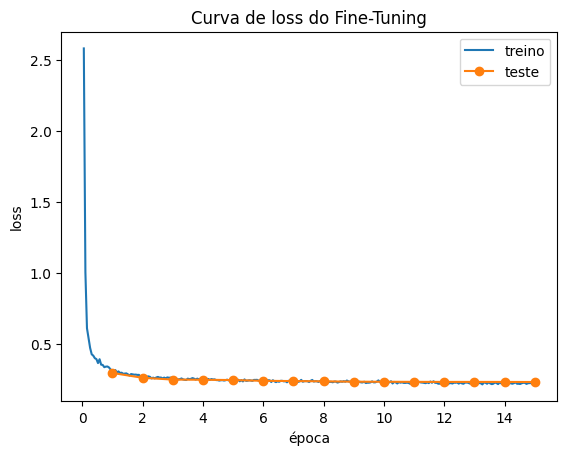

Training Loss,Validation Loss,Epoch
0.224857,0.234232,15


,modelo,loss_teste,perplexidade
0,base (antes),4.467,87.104
1,fine-tuned (depois),0.234,1.264


In [ ]:
historico = trainer_pt.state.log_history
loss_treino = [(h["epoch"], h["loss"]) for h in historico if "loss" in h]
loss_teste = [(h["epoch"], h["eval_loss"]) for h in historico if "eval_loss" in h]

plt.plot(*zip(*loss_treino), label="treino")
plt.plot(*zip(*loss_teste), marker="o", label="teste")
plt.xlabel("época")
plt.ylabel("loss")
plt.title("Curva de loss do Fine-Tuning")
plt.legend()
plt.show()

depois = trainer_pt.evaluate()

tabela_perplexidade = pd.DataFrame({
    "modelo": ["base (antes)", "fine-tuned (depois)"],
    "loss_teste": [antes["eval_loss"], depois["eval_loss"]],
    "perplexidade": [math.exp(antes["eval_loss"]), math.exp(depois["eval_loss"])],
})
tabela_perplexidade.to_csv(f"{PASTA}/perplexidade.csv", index=False)
display(tabela_perplexidade.round(3))

## Passo 9: gerador
Carregando o modelo treinado e criando a função `gerar`, igual à `perguntar_ia_brasil` da aula. A `limpar_resposta` pega só o texto até o `[FIM]`.

In [ ]:
from transformers import pipeline, set_seed

caminho_modelo = f"{PASTA}/modelo_garoavisa_ia"

gerador_pt = pipeline("text-generation", model=caminho_modelo, tokenizer=caminho_modelo, device=0)

def criar_gerador(pipe, temperatura=0.7):
    def gerar(pergunta):
        prompt = f"Pergunta: {pergunta} Resposta:"
        resultado = pipe(prompt, max_new_tokens=120, do_sample=True, temperature=temperatura, pad_token_id=tokenizer_pt.eos_token_id)
        return ga.limpar_resposta(resultado[0]["generated_text"])
    return gerar

gerar_ia = criar_gerador(gerador_pt, 0.7)

print("Gerador pronto")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Gerador pronto


## Passo 10: Integração da IA ao Fluxo de Validação

Execução do fluxo completo com as previsões reais, onde as regras calculam os alertas, a IA gera a explicação e o validador confere o resultado. Caso o texto seja reprovado, o sistema recorre ao texto padrão baseado em regras, registrando no campo `origem` qual método gerou a resposta final.

In [ ]:
for nome, dias in previsoes.items():
    hoje = dias[0]
    resultado = ga.explicar("dia", hoje, gerar_ia)
    print("Local:", nome, "| data:", hoje["data"], "| origem:", resultado["origem"])
    print(resultado["texto"])
    if resultado["motivos"]:
        print("motivos:", resultado["motivos"])
    print()

Local: Tatuapé (São Paulo) | data: 2026-11-16 | origem: ia
Hoje a máxima será de 24°C e a mínima de 18°C. Radiação UV em nível médio, com índice máximo de 9. Chuva prevista, nível baixo: 100% de chance e até 2 mm/h. Dica do dia: use protetor solar e óculos e evite o sol das 10h às 16h.

Local: Bela Vista (São Paulo) | data: 2026-11-16 | origem: ia
Hoje a máxima será de 24°C e a mínima de 19°C. Radiação UV em nível médio, com índice máximo de 9. Chuva prevista, nível baixo: 100% de chance e até 1.3 mm/h. Dica do dia: use protetor solar e óculos e evite o sol das 10h às 16h.

Local: Centro (Guarulhos) | data: 2026-11-16 | origem: ia
A previsão de hoje é de máxima de 24°C e mínima de 18°C. Radiação UV em nível médio, com índice máximo de 9. Chuva prevista, nível baixo: 100% de chance e até 1 mm/h. Dica do dia: use protetor solar e óculos e evite o sol das 10h às 16h.

Local: Copacabana (Rio de Janeiro) | data: 2026-11-16 | origem: ia
Hoje a máxima será de 27°C e a mínima de 22°C. Radiação

## Passo 11: Notificação de Alteração Climática em Compromissos

Simulação do alerta de mudança de previsão para o compromisso *"Dia de praia"* (Gonzaga, Santos). Como a API da Open-Meteo não fornece histórico de previsões passadas, o cenário inicial é simulado e comparado com a previsão real obtida para o dia seguinte, acionando a IA e o validador para gerar o aviso.

In [ ]:
amanha_santos = previsoes["Gonzaga (Santos)"][1]

mudanca_praia = {
    "nome": "Dia de praia",
    "tmax_antes": 30,
    "chuva_antes": 20,
    "tmax_agora": amanha_santos["tmax"],
    "chuva_agora": amanha_santos["chuva_prob"],
}

print("Dados:", mudanca_praia)
resultado = ga.explicar("mudanca", mudanca_praia, gerar_ia)
print("origem:", resultado["origem"])
print(resultado["texto"])
if resultado["motivos"]:
    print("motivos:", resultado["motivos"])

Dados: {'nome': 'Dia de praia', 'tmax_antes': 30, 'chuva_antes': 20, 'tmax_agora': 26, 'chuva_agora': 78}
origem: ia
Atenção, o clima de Dia de praia mudou: a chance de chuva subiu de 20% para 78% e a máxima caiu de 30°C para 26°C. Leve guarda-chuva ou reveja o plano.


## Passo 12: Avaliação de Fidelidade das Respostas

Teste comparativo entre o modelo base (sem treino) e o modelo treinado (*fine-tuned*) usando 100 exemplos inéditos do conjunto de teste. O validador analisa as respostas diretamente, sem recorrer ao texto padrão por regras, para calcular a taxa de acerto em cada tarefa (`dia` e `mudanca`) e exibir exemplos das falhas encontradas.

In [ ]:
gerador_base = pipeline("text-generation", model=model_name_pt, device=0)
gerar_base = criar_gerador(gerador_base, 0.7)

amostra = random.Random(7).sample(teste_itens, 100)

def avaliar(gerar):
    linhas = []
    for item in amostra:
        texto = gerar(item["question"])
        valido, falhas = ga.validar(item["tarefa"], item["dados"], item["question"], texto)
        linhas.append({"tarefa": item["tarefa"], "valido": valido, "falhas": falhas, "texto": texto})
    return pd.DataFrame(linhas)

set_seed(42)
res_ia = avaliar(gerar_ia)

set_seed(42)
res_base = avaliar(gerar_base)

def taxa(res, tarefa=None):
    parte = res if tarefa is None else res[res["tarefa"] == tarefa]
    return parte["valido"].mean() * 100

resumo = pd.DataFrame({
    "modelo": ["base (sem treino)", "fine-tuned"],
    "fidelidade_geral_%": [taxa(res_base), taxa(res_ia)],
    "dia_%": [taxa(res_base, "dia"), taxa(res_ia, "dia")],
    "mudanca_%": [taxa(res_base, "mudanca"), taxa(res_ia, "mudanca")],
})
resumo.to_csv(f"{PASTA}/fidelidade.csv", index=False)
display(resumo.round(1))

reprovados = res_ia[~res_ia["valido"]]
print("Reprovados no fine-tuned:", len(reprovados))
for _, linha in reprovados.head(3).iterrows():
    print("tarefa:", linha["tarefa"])
    print("texto:", linha["texto"])
    print("falhas:", linha["falhas"])
    print()

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: pierreguillou/gpt2-small-portuguese
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,modelo,fidelidade_geral_%,dia_%,mudanca_%
0,base (sem treino),0.0,0.0,0.0
1,fine-tuned,100.0,100.0,100.0


Reprovados no fine-tuned: 0


## Passo 13: Bateria de Casos de Teste e Borda

Validação do sistema em 16 cenários controlados, abrangendo dias típicos, condições extremas, valores exatamente nos limites das regras, cenários com múltiplos alertas simultâneos e entradas com dados ausentes. O teste verifica o comportamento completo da geração de texto, do validador e do acionamento do *fallback* por regras, salvando os resultados em CSV.

In [ ]:
base = {"tmax": 26, "tmin": 18, "uv": 5, "chuva_prob": 20, "chuva_mm_h": 0, "vento": 20, "umid_min": 60, "semana_seca": False}

def dia(**alteracoes):
    return {**base, **alteracoes}

casos = [
    ("dia", "Dia típico, sem alertas", dia()),
    ("dia", "Calor e UV altos (como no banco)", dia(tmax=34, tmin=22, uv=11, umid_min=40)),
    ("dia", "Chuva forte: 85% e 12 mm/h", dia(chuva_prob=85, chuva_mm_h=12, umid_min=80)),
    ("dia", "Rajadas de 62 km/h", dia(vento=62)),
    ("dia", "Ar seco com calor", dia(tmax=33, tmin=21, umid_min=24)),
    ("dia", "Frio e grande amplitude", dia(tmax=24, tmin=11)),
    ("dia", "Semana sem chuva", dia(semana_seca=True)),
    ("dia", "Exatamente nos limites das regras", dia(tmax=30, tmin=22, uv=8, chuva_prob=60, chuva_mm_h=3, vento=50)),
    ("dia", "Logo abaixo dos limites", dia(tmax=29, tmin=21, uv=7, chuva_prob=59, vento=49)),
    ("dia", "Mais de 3 alertas", dia(tmax=36, tmin=20, uv=12, chuva_prob=90, chuva_mm_h=14, vento=80, umid_min=20, semana_seca=True)),
    ("dia", "Falha: UV ausente", dia(uv=None)),
    ("dia", "Falha: nenhum dado", {}),
    ("mudanca", "Praia: chuva sobe e máxima cai", {"nome": "Dia de praia", "tmax_antes": 30, "chuva_antes": 20, "tmax_agora": 24, "chuva_agora": 80}),
    ("mudanca", "Praia: máxima sobe", {"nome": "Dia de praia", "tmax_antes": 25, "chuva_antes": 10, "tmax_agora": 33, "chuva_agora": 15}),
    ("mudanca", "Mudança pequena", {"nome": "Churrasco em família", "tmax_antes": 28, "chuva_antes": 30, "tmax_agora": 29, "chuva_agora": 35}),
    ("mudanca", "Falha: chuva atual ausente", {"nome": "Dia de praia", "tmax_antes": 28, "chuva_antes": 30, "tmax_agora": 29, "chuva_agora": None}),
]

set_seed(42)
linhas = []
for tarefa, descricao, dados in casos:
    resultado = ga.explicar(tarefa, dados, gerar_ia)
    linhas.append({
        "tarefa": tarefa,
        "caso": descricao,
        "origem": resultado["origem"],
        "texto": resultado["texto"],
        "motivos": "; ".join(resultado["motivos"]),
    })

tabela_casos = pd.DataFrame(linhas)
tabela_casos.to_csv(f"{PASTA}/casos_de_teste.csv", index=False, encoding="utf-8")

pd.set_option("display.max_colwidth", None)
display(tabela_casos)
print(tabela_casos["origem"].value_counts())

,tarefa,caso,origem,texto,motivos
0,dia,"Dia típico, sem alertas",ia,"A previsão de hoje é de máxima de 26°C e mínima de 18°C. Dia tranquilo, sem alertas. Dica do dia: aproveite o dia com tranquilidade.",
1,dia,Calor e UV altos (como no banco),ia,"Hoje a máxima será de 34°C e a mínima de 22°C. Alerta de UV (nível alto): índice máximo de 11. Calor previsto, nível médio, com máxima de 34°C. A temperatura muda muito no dia, nível baixo: de 22°C a 34°C. Dica do dia: use protetor solar e óculos e evite o sol das 10h às 16h.",
2,dia,Chuva forte: 85% e 12 mm/h,ia,"Hoje a máxima será de 26°C e a mínima de 18°C. Chuva prevista, nível alto: 85% de chance e até 12 mm/h. Dica do dia: leve guarda-chuva.",
3,dia,Rajadas de 62 km/h,ia,"A previsão de hoje é de máxima de 26°C e mínima de 18°C. Vento forte previsto, nível médio, com rajadas de até 62 km/h. Dica do dia: cuidado com árvores, placas e fios, e não estacione embaixo de árvores.",
4,dia,Ar seco com calor,ia,"Hoje a máxima será de 33°C e a mínima de 21°C. Alerta de calor (nível médio): máxima de 33°C. Alerta de amplitude térmica (nível baixo): 21°C de manhã e 33°C à tarde. Umidade baixa, nível baixo: 24% à tarde. Dica do dia: leve garrafa de água e use roupa leve.",
5,dia,Frio e grande amplitude,ia,"Hoje a máxima será de 24°C e a mínima de 11°C. Alerta de frio (nível baixo): mínima de 11°C. A temperatura muda muito no dia, nível baixo: de 11°C a 24°C. Dica do dia: leve um casaco.",
6,dia,Semana sem chuva,ia,"Hoje a máxima será de 26°C e a mínima de 18°C. Semana sem chuva prevista, nível baixo. Dica do dia: economize água e regue as plantas à noite, pois há risco de queimadas.",
7,dia,Exatamente nos limites das regras,ia,"Hoje a máxima será de 30°C e a mínima de 22°C. Calor previsto, nível médio, com máxima de 30°C. Radiação UV em nível médio, com índice máximo de 8. Vento forte previsto, nível médio, com rajadas de até 50 km/h. Dica do dia: leve garrafa de água e use roupa leve.",
8,dia,Logo abaixo dos limites,ia,"Hoje a máxima será de 29°C e a mínima de 21°C. Dia tranquilo, sem alertas. Dica do dia: beba água ao longo do dia.",
9,dia,Mais de 3 alertas,ia,"A previsão de hoje é de máxima de 36°C e mínima de 20°C. Chuva prevista, nível alto: 90% de chance e até 14 mm/h. Calor previsto, nível alto, com máxima de 36°C. Radiação UV em nível alto, com índice máximo de 12. Dica do dia: leve guarda-chuva.",


origem
ia              13
indisponivel     3
Name: count, dtype: int64


## Passo 14: Teste de Resiliência e Fallback

Simulação de falhas propositais na geração de texto utilizando dois modelos fictícios, um que alucina dados numéricos inconsistentes e outro que retorna uma saída vazia, para comprovar que o validador intercepta os erros e aciona corretamente o texto padrão baseado em regras.

In [ ]:
d = dia(tmax=34, tmin=22, uv=11, umid_min=40)

def modelo_inventa(pergunta):
    return "Hoje fará 99°C e vai chover muito."

def modelo_vazio(pergunta):
    return ""

for nome, modelo in [("inventa número", modelo_inventa), ("não escreve nada", modelo_vazio)]:
    resultado = ga.explicar("dia", d, modelo)
    print(nome, "-> origem:", resultado["origem"])
    print("texto:", resultado["texto"])
    print("motivos:", resultado["motivos"])
    print()

inventa número -> origem: regra
texto: Hoje a máxima será de 34°C e a mínima de 22°C. Alerta de UV (nível alto): índice máximo de 11. Alerta de calor (nível médio): máxima de 34°C. Alerta de amplitude térmica (nível baixo): 22°C de manhã e 34°C à tarde. Dica do dia: use protetor solar e óculos e evite o sol das 10h às 16h.
motivos: ['números que não estavam nos dados: [99.0]', 'alerta UV não foi explicado', 'alerta CALOR não foi explicado', 'alerta AMPLITUDE não foi explicado', 'sem dica do dia', 'frase fora do esperado: Hoje fará 99°C e vai chover muito.', 'quantidade de frases diferente do esperado: 1']

não escreve nada -> origem: regra
texto: Hoje a máxima será de 34°C e a mínima de 22°C. Alerta de UV (nível alto): índice máximo de 11. Alerta de calor (nível médio): máxima de 34°C. Alerta de amplitude térmica (nível baixo): 22°C de manhã e 34°C à tarde. Dica do dia: use protetor solar e óculos e evite o sol das 10h às 16h.
motivos: ['texto vazio ou curto', 'alerta UV não foi explic